# Imports

In [1]:
import kagglehub
import pandas as pd
from pathlib import Path
import os
import matplotlib.pyplot as plt

/Users/jaredpaul/Coding/Predictive-Maintenance-RCA/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(
/Users/jaredpaul/Coding/Predictive-Maintenance-RCA/.venv/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Download Data

In [2]:
path = kagglehub.dataset_download("arnabbiswas1/microsoft-azure-predictive-maintenance")
path

'/Users/jaredpaul/.cache/kagglehub/datasets/arnabbiswas1/microsoft-azure-predictive-maintenance/versions/3'

# Helper Function

In [3]:
def general_analysis(df):
    print(f"Dataframe Shape:\n {df.shape}\n")
    print(f"Column Types:\n{df.dtypes}\n")
    print(f"Num of Missing Values Per Col:\n{df.isna().sum()}\n")
    print(f"Num of Duplicated Rows:\n{df.duplicated().sum()}\n")
    if 'datetime' in df.columns:
        print(f"Date Range:\n{df['datetime'].min()} - {df['datetime'].max()}")

# Load Data as Dataframes 

In [4]:
os.listdir(path)

['PdM_maint.csv',
 'PdM_errors.csv',
 'PdM_machines.csv',
 'PdM_failures.csv',
 'PdM_telemetry.csv']

In [5]:
maintenance_df = pd.read_csv(f"{path}/PdM_maint.csv", parse_dates=['datetime'])
errors_df = pd.read_csv(f"{path}/PdM_errors.csv", parse_dates=['datetime'])
machines_df = pd.read_csv(f"{path}/PdM_machines.csv")
failures_df = pd.read_csv(f"{path}/PdM_failures.csv", parse_dates=['datetime'])
telemetry_df = pd.read_csv(f"{path}/PdM_telemetry.csv", parse_dates=['datetime'])

In [6]:
df_dicts = {'maintenance' : maintenance_df, 'errors': errors_df, 'machines': machines_df, 'failures':failures_df, 'telemetry':telemetry_df}

# Quick View

In [7]:
for name,df in df_dicts.items():
    print(name)
    display(df.head())
    print("\n")

maintenance


,datetime,machineID,comp
0,2014-06-01 06:00:00,1,comp2
1,2014-07-16 06:00:00,1,comp4
2,2014-07-31 06:00:00,1,comp3
3,2014-12-13 06:00:00,1,comp1
4,2015-01-05 06:00:00,1,comp4




errors


,datetime,machineID,errorID
0,2015-01-03 07:00:00,1,error1
1,2015-01-03 20:00:00,1,error3
2,2015-01-04 06:00:00,1,error5
3,2015-01-10 15:00:00,1,error4
4,2015-01-22 10:00:00,1,error4




machines


,machineID,model,age
0,1,model3,18
1,2,model4,7
2,3,model3,8
3,4,model3,7
4,5,model3,2




failures


,datetime,machineID,failure
0,2015-01-05 06:00:00,1,comp4
1,2015-03-06 06:00:00,1,comp1
2,2015-04-20 06:00:00,1,comp2
3,2015-06-19 06:00:00,1,comp4
4,2015-09-02 06:00:00,1,comp4




telemetry


,datetime,machineID,volt,rotate,pressure,vibration
0,2015-01-01 06:00:00,1,176.217853,418.504078,113.077935,45.087686
1,2015-01-01 07:00:00,1,162.879223,402.747490,95.460525,43.413973
2,2015-01-01 08:00:00,1,170.989902,527.349825,75.237905,34.178847
3,2015-01-01 09:00:00,1,162.462833,346.149335,109.248561,41.122144
4,2015-01-01 10:00:00,1,157.610021,435.376873,111.886648,25.990511


# Maintenance EDA

<b>Dataset Description (from Kaggle):</b><br>
These are the scheduled and unscheduled maintenance records which correspond to both regular inspection of components as well as failures. A record is generated if a component is replaced during the scheduled inspection or replaced due to a breakdown. The records that are created due to breakdowns will be called failures which is explained in the later sections. Maintenance data has both 2014 and 2015 records.

**What to look for:**
1. What does Data look like?
2. How are maintenance records split across components?
3. Do all machines have maintenance records?
4. How many maintenance records does each machine have?
5. How often is each component replaced (days between replacements)?


In [8]:
general_analysis(maintenance_df)

Dataframe Shape:
 (3286, 3)

Column Types:
datetime     datetime64[ns]
machineID             int64
comp                 object
dtype: object

Num of Missing Values Per Col:
datetime     0
machineID    0
comp         0
dtype: int64

Num of Duplicated Rows:
0

Date Range:
2014-06-01 06:00:00 - 2016-01-01 06:00:00


In [9]:
maintenance_df

,datetime,machineID,comp
0,2014-06-01 06:00:00,1,comp2
1,2014-07-16 06:00:00,1,comp4
2,2014-07-31 06:00:00,1,comp3
3,2014-12-13 06:00:00,1,comp1
4,2015-01-05 06:00:00,1,comp4
...,...,...,...
3281,2015-10-10 06:00:00,100,comp3
3282,2015-10-25 06:00:00,100,comp4
3283,2015-11-09 06:00:00,100,comp4
3284,2015-12-09 06:00:00,100,comp2


In [10]:
maintenance_df['comp'].nunique()

4

In [11]:
maintenance_df['comp'].value_counts()

comp
comp2    863
comp4    811
comp3    808
comp1    804
Name: count, dtype: int64

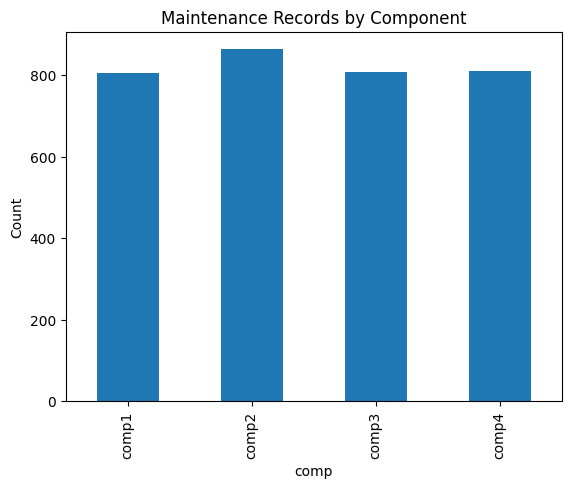

In [12]:
maintenance_df['comp'].value_counts().sort_index().plot(kind='bar')
plt.title('Maintenance Records by Component')
plt.ylabel('Count')
plt.show()

In [13]:
maintenance_df['machineID'].nunique()

100

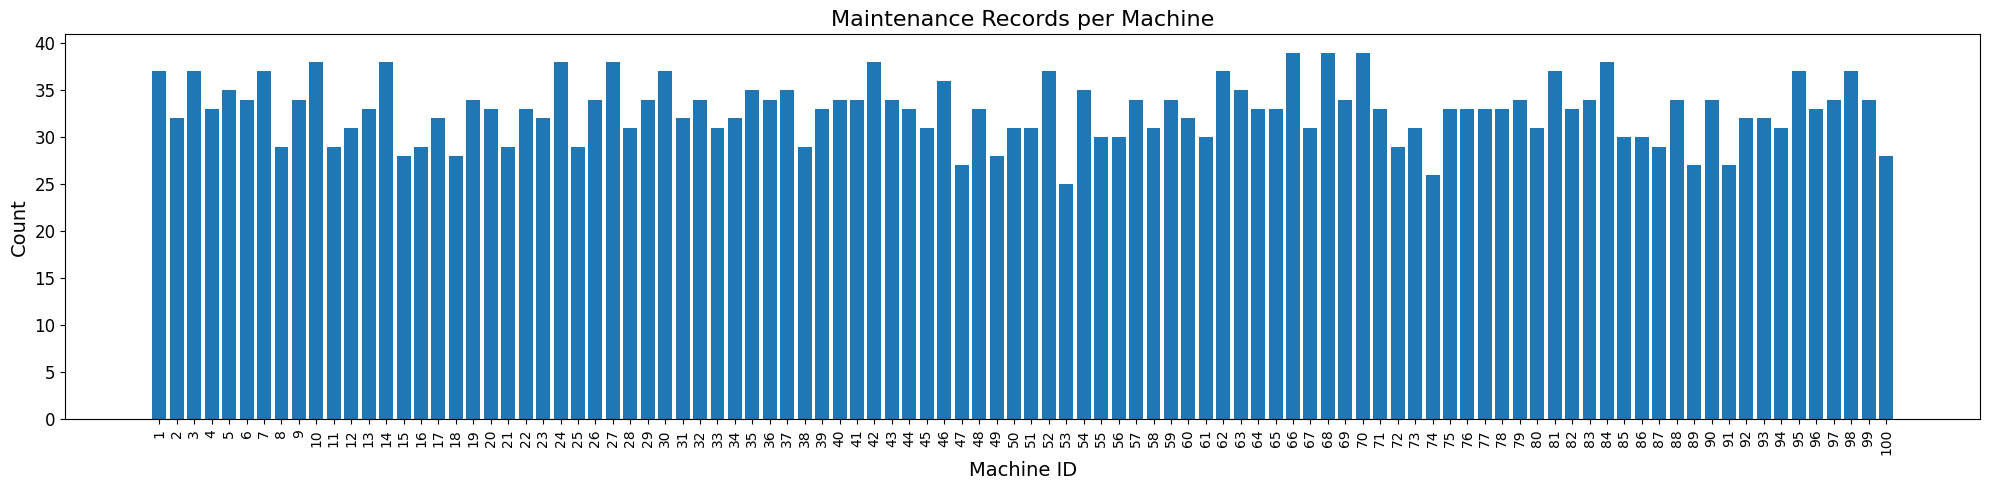

In [14]:
counts = maintenance_df['machineID'].value_counts().sort_index().reset_index()
counts.columns = ['machineID', 'count']

plt.figure(figsize=(20, 5))
plt.bar(counts['machineID'], counts['count'])
plt.xticks(counts['machineID'], rotation=90, fontsize=10)
plt.yticks(fontsize=12)
plt.title('Maintenance Records per Machine', fontsize=16)
plt.xlabel('Machine ID', fontsize=14)
plt.ylabel('Count', fontsize=14)
plt.tight_layout()
plt.show()


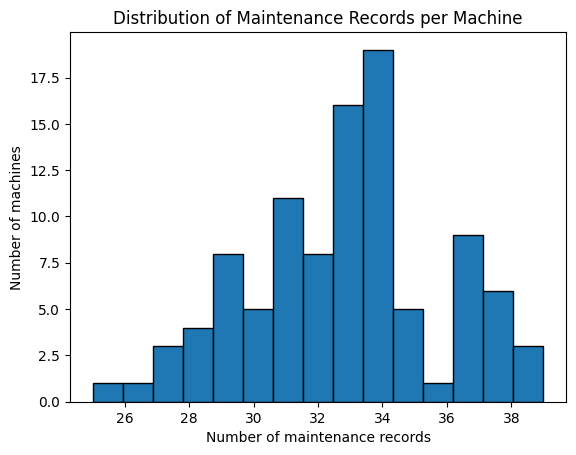

In [15]:
plt.hist(counts['count'], bins=15, edgecolor='black')
plt.title('Distribution of Maintenance Records per Machine')
plt.xlabel('Number of maintenance records')
plt.ylabel('Number of machines')
plt.show()


<b>calculate the number of days between maintenance records for each machine/comp

In [16]:
maintenance_modified_df = maintenance_df.sort_values(["machineID", "comp", "datetime"])
maintenance_modified_df["days_since_prev"] = maintenance_modified_df.groupby(["machineID", "comp"])["datetime"].diff().dt.days
maintenance_modified_df["prev_datetime"] = maintenance_modified_df.groupby(["machineID", "comp"])["datetime"].shift()
maintenance_modified_df

,datetime,machineID,comp,days_since_prev,prev_datetime
3,2014-12-13 06:00:00,1,comp1,NaN,NaT
5,2015-01-05 06:00:00,1,comp1,23.0,2014-12-13 06:00:00
7,2015-01-20 06:00:00,1,comp1,15.0,2015-01-05 06:00:00
11,2015-03-06 06:00:00,1,comp1,45.0,2015-01-20 06:00:00
12,2015-03-21 06:00:00,1,comp1,15.0,2015-03-06 06:00:00
...,...,...,...,...,...
3268,2015-04-28 06:00:00,100,comp4,90.0,2015-01-28 06:00:00
3271,2015-05-28 06:00:00,100,comp4,30.0,2015-04-28 06:00:00
3277,2015-08-26 06:00:00,100,comp4,90.0,2015-05-28 06:00:00
3282,2015-10-25 06:00:00,100,comp4,60.0,2015-08-26 06:00:00


In [17]:
maintenance_modified_df.groupby("comp")["days_since_prev"].describe()

,count,mean,std,min,25%,50%,75%,max
comp,,,,,,,,
comp1,704.0,61.122159,59.631914,11.0,15.0,45.0,75.0,492.0
comp2,763.0,57.241153,59.276008,5.0,15.0,30.0,75.0,349.0
comp3,708.0,62.005650,59.838089,15.0,15.0,45.0,75.0,371.0
comp4,711.0,61.638537,60.577341,15.0,15.0,45.0,75.0,395.0


In [18]:
maintenance_modified_df.groupby("comp")["days_since_prev"].quantile(0.95)

comp
comp1    188.8
comp2    190.4
comp3    200.3
comp4    196.0
Name: days_since_prev, dtype: float64

/var/folders/h3/58sb5ybx6fzgy8l9n1029qd80000gn/T/ipykernel_29582/3010749240.py:1: FutureWarning: 'Me' is deprecated and will be removed in a future version, please use 'ME' instead.
  maintenance_df.set_index("datetime").resample("Me").size().plot(kind="bar", figsize=(12, 4))


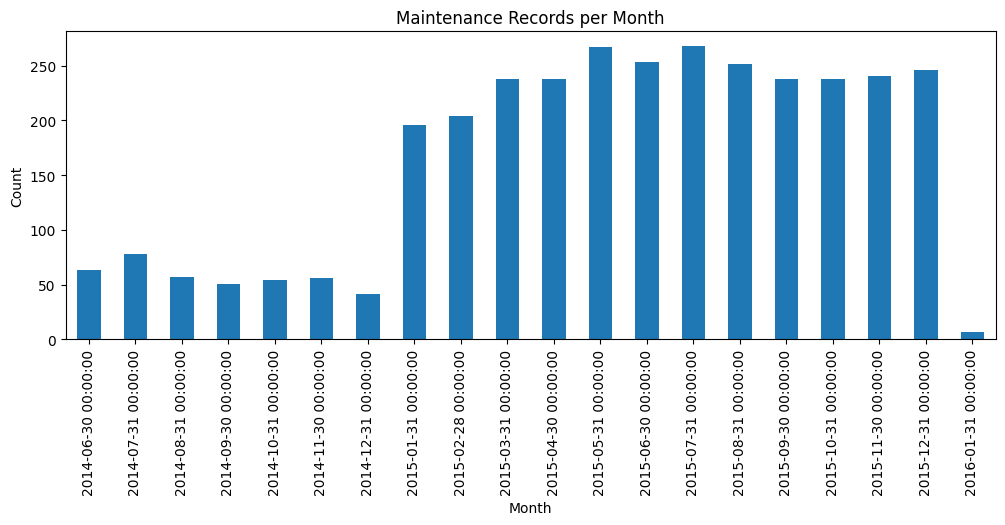

In [19]:
maintenance_df.set_index("datetime").resample("Me").size().plot(kind="bar", figsize=(12, 4))
plt.title("Maintenance Records per Month")
plt.ylabel("Count")
plt.xlabel("Month")
plt.show()


<b> Check how of the large maintenace gaps were prior to 2015

In [20]:
outliers = maintenance_modified_df[maintenance_modified_df["days_since_prev"] > 200]
(outliers["prev_datetime"] < "2015-01-01").value_counts()

prev_datetime
True     127
False      8
Name: count, dtype: int64

**Findings:**
- The data is Clean with no missing values or Duplicates.
- There are 4 components with each having a pretty even spread of maintenance records.
- Maintenace records are quite evenly distributed among all 100 machines as well.
- Component 2 is typically replaced every 30 days, while components 1,3,4 are replaced every 45.
- The data from 2014 is distinct and potentially unreliable here as it has 4x less records per months than 2015 and almost all the large gaps between replacements(majority of the outliers)


# Errors EDA
<b>Dataset Description (from Kaggle):</b><br>
This data represents error logs. These are non-breaking errors thrown while the machine is still operational and do not constitute as failures. The error date and times are rounded to the closest hour since the telemetry data is collected at an hourly rate.

**What to look for:**
1. What does the data look like
2. How common is each error type?
3. How many errors does each machine have?
4. How often does the same error repeat on a machine?


In [21]:
general_analysis(errors_df)

Dataframe Shape:
 (3919, 3)

Column Types:
datetime     datetime64[ns]
machineID             int64
errorID              object
dtype: object

Num of Missing Values Per Col:
datetime     0
machineID    0
errorID      0
dtype: int64

Num of Duplicated Rows:
0

Date Range:
2015-01-01 06:00:00 - 2016-01-01 05:00:00


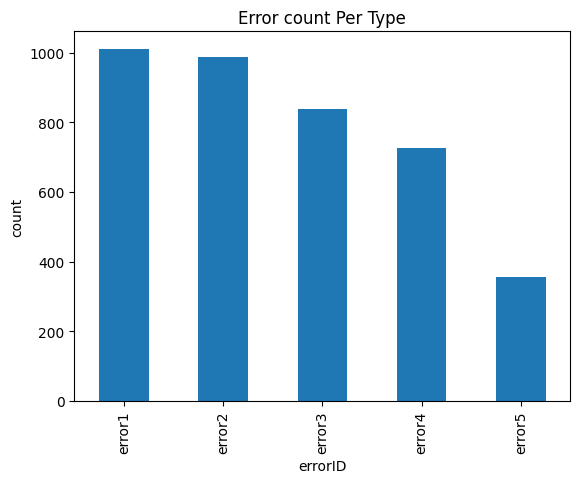

In [22]:
errors_df['errorID'].value_counts().plot(kind='bar')
plt.title('Error count Per Type')
plt.ylabel('count')
plt.show()

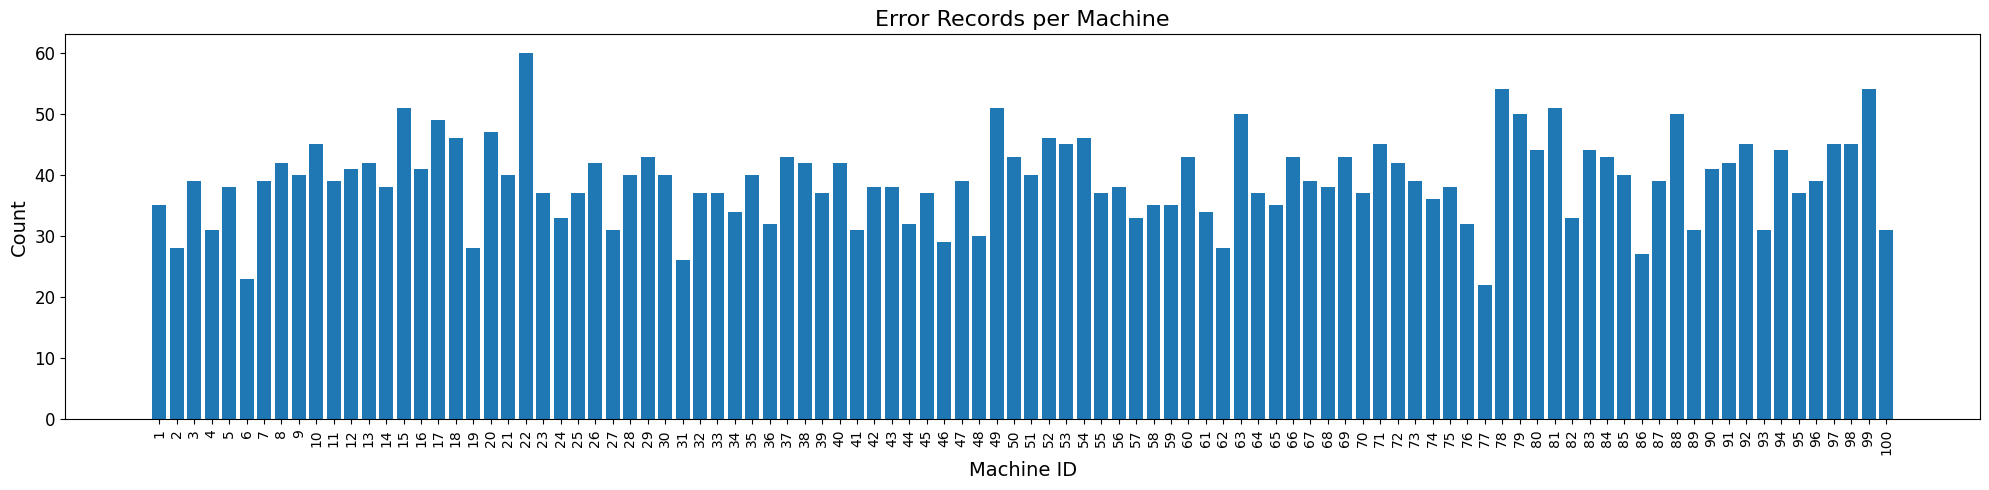

In [23]:
counts = errors_df['machineID'].value_counts().sort_index().reset_index()
counts.columns = ['machineID', 'count']

plt.figure(figsize=(20, 5))
plt.bar(counts['machineID'], counts['count'])
plt.xticks(counts['machineID'], rotation=90, fontsize=10)
plt.yticks(fontsize=12)
plt.title('Error Records per Machine', fontsize=16)
plt.xlabel('Machine ID', fontsize=14)
plt.ylabel('Count', fontsize=14)
plt.tight_layout()
plt.show()


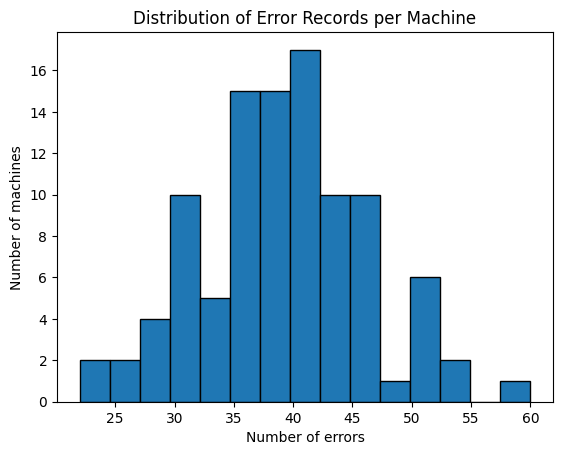

In [24]:
plt.hist(counts['count'], bins=15, edgecolor='black')
plt.title('Distribution of Error Records per Machine')
plt.xlabel('Number of errors')
plt.ylabel('Number of machines')
plt.show()


In [25]:
counts["count"].describe()

count    100.000000
mean      39.190000
std        6.882411
min       22.000000
25%       35.000000
50%       39.000000
75%       43.000000
max       60.000000
Name: count, dtype: float64

In [26]:
e = errors_df.sort_values(["machineID", "errorID", "datetime"])
e["hours_since_prev"] = e.groupby(["machineID", "errorID"])["datetime"].diff().dt.total_seconds() / 3600
e.groupby("errorID")["hours_since_prev"].describe()

,count,mean,std,min,25%,50%,75%,max
errorID,,,,,,,,
error1,910.0,763.403297,720.157513,2.0,227.25,565.5,1062.00,4642.0
error2,888.0,797.889640,727.390720,2.0,276.75,603.0,1080.00,4891.0
error3,738.0,901.506775,840.547950,2.0,310.25,703.0,1234.25,5937.0
error4,627.0,993.902711,898.070035,3.0,303.50,763.0,1440.00,5774.0
error5,263.0,1517.490494,1132.101710,6.0,611.50,1383.0,2160.00,5351.0


**Findings:**
- Data is clean with no missing values or duplicates
- There are 5 error types which are appear unevenly. Error 1 the most, and error 5 the least.
- Errors are quite evenly spread across all machines, with a median of 39 and ranging from 22-60.
- The same error does not frequently repeat on a machine, with the median gap range between 24 to 58 days. 

# Machines EDA
<b>Dataset Description (from Kaggle):</b><br>
This data set includes meta-data about the machines: model type and age (years in service).

**What to look for:**
1. What does the data look like?
2. How many machines are there of each model?
3. How old are the machines?
4. Does machine age differ by model?


In [27]:
general_analysis(machines_df)

Dataframe Shape:
 (100, 3)

Column Types:
machineID     int64
model        object
age           int64
dtype: object

Num of Missing Values Per Col:
machineID    0
model        0
age          0
dtype: int64

Num of Duplicated Rows:
0



In [28]:
#machines_df.head(20)

Text(0, 0.5, 'Count')

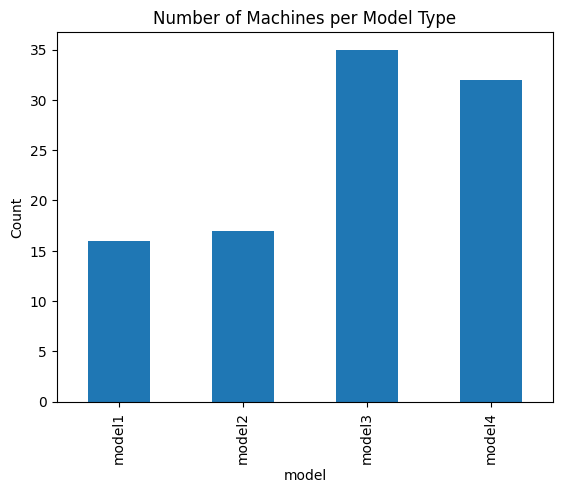

In [29]:
machines_df['model'].value_counts().sort_index().plot(kind='bar')
plt.title('Number of Machines per Model Type')
plt.ylabel('Count')

In [30]:
machines_df["age"].describe()

count    100.000000
mean      11.330000
std        5.856974
min        0.000000
25%        6.750000
50%       12.000000
75%       16.000000
max       20.000000
Name: age, dtype: float64

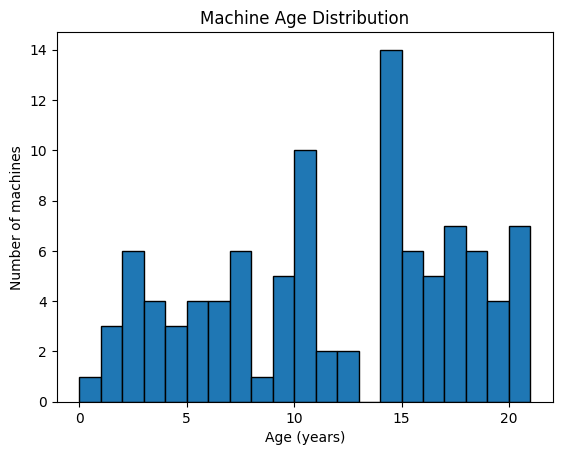

In [31]:
plt.hist(machines_df["age"], bins=range(0, 22), edgecolor="black")
plt.xlabel("Age (years)")
plt.ylabel("Number of machines")
plt.title("Machine Age Distribution")
plt.show()

In [32]:
machines_df.groupby('model')['age'].describe()

,count,mean,std,min,25%,50%,75%,max
model,,,,,,,,
model1,16.0,12.250000,5.385165,2.0,9.25,14.0,16.00,20.0
model2,17.0,12.764706,5.847322,2.0,10.00,14.0,18.00,20.0
model3,35.0,12.028571,5.607168,1.0,8.50,14.0,17.00,20.0
model4,32.0,9.343750,6.099230,0.0,4.00,9.5,14.25,20.0


**Findings:**
- The data is clean with no missing Values or duplicates
- The number of machines are unevenly split amongst for 4 different models
- Model 4 has the youngest mean age of about 9 with the others at around 12-13 

# Failures EDA
<b>Dataset Description (from Kaggle):</b><br>
These are the records of component replacements due to failures. Each record has a date and time, machine ID, and failed component type.

**What to look for:**
1. What does the data look like?
2. How common is each component failure?
3. How many failures does each machine have?
4. How many distinct events?
5. How much time passes between events on the same machine?
6. Are events spread evenly through the year?

In [33]:
general_analysis(failures_df)

Dataframe Shape:
 (761, 3)

Column Types:
datetime     datetime64[ns]
machineID             int64
failure              object
dtype: object

Num of Missing Values Per Col:
datetime     0
machineID    0
failure      0
dtype: int64

Num of Duplicated Rows:
0

Date Range:
2015-01-02 03:00:00 - 2015-12-31 06:00:00


Text(0, 0.5, 'Count')

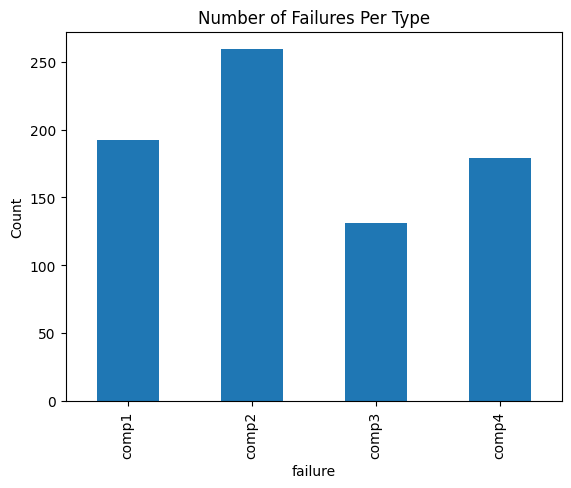

In [34]:
failures_df['failure'].value_counts().sort_index().plot(kind='bar')
plt.title('Number of Failures Per Type')
plt.ylabel('Count')

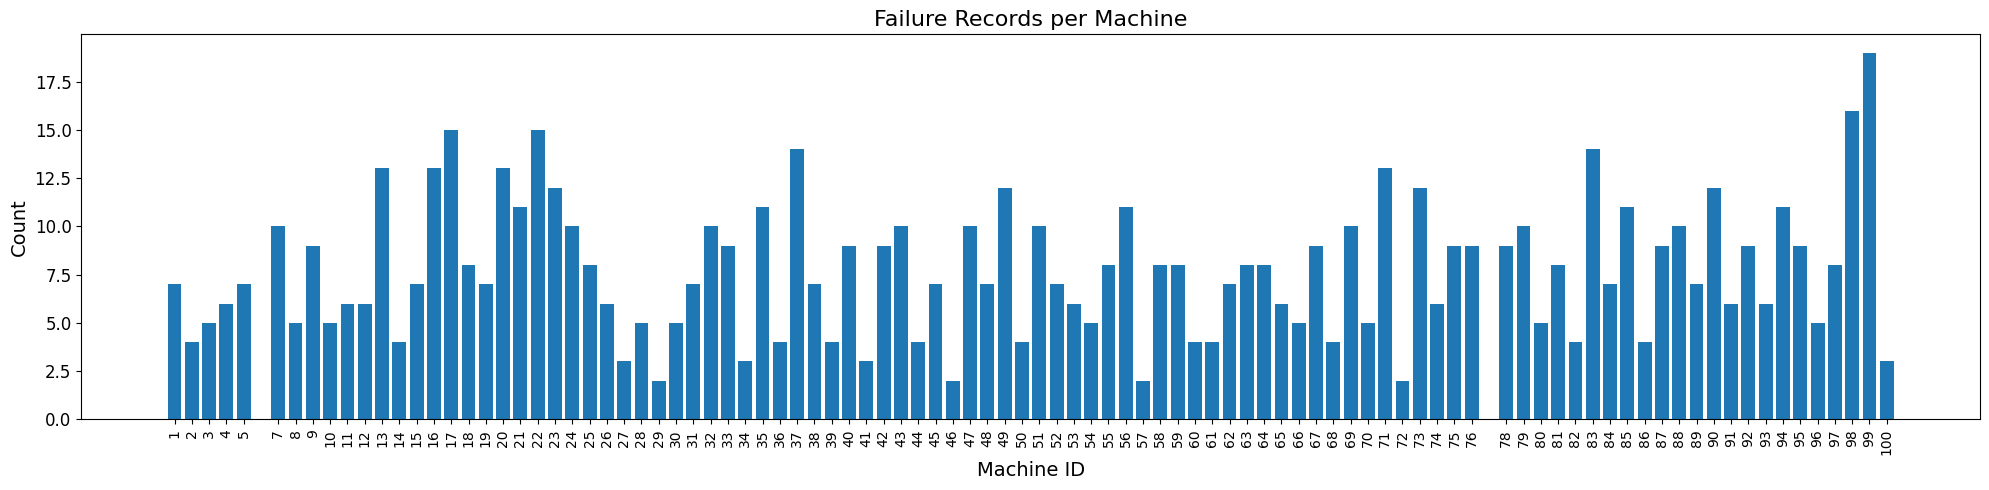

In [35]:
counts = failures_df['machineID'].value_counts().sort_index().reset_index()
counts.columns = ['machineID', 'count']

plt.figure(figsize=(20, 5))
plt.bar(counts['machineID'], counts['count'])
plt.xticks(counts['machineID'], rotation=90, fontsize=10)
plt.yticks(fontsize=12)
plt.title('Failure Records per Machine', fontsize=16)
plt.xlabel('Machine ID', fontsize=14)
plt.ylabel('Count', fontsize=14)
plt.tight_layout()
plt.show()


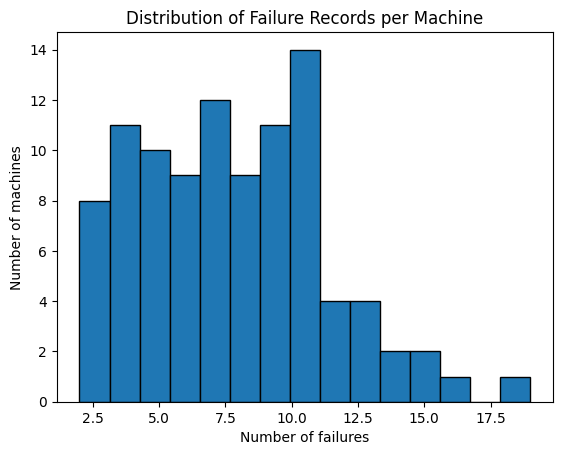

In [36]:
plt.hist(counts['count'], bins=15, edgecolor='black')
plt.title('Distribution of Failure Records per Machine')
plt.xlabel('Number of failures')
plt.ylabel('Number of machines')
plt.show()


<b> Calculate failure events which group up any failures of a given machine that occur at the same time.

In [37]:
events_df = failures_df.groupby(["machineID", "datetime"])['failure'].apply(sorted).reset_index()

In [38]:
#events_df

In [39]:
print(f"Number of Failure Occurences: {len(failures_df)}")
print(f"Number of Failure Events: {len(events_df)}")

Number of Failure Occurences: 761
Number of Failure Events: 719


Failure combinations in events with their occurences

In [40]:
print(events_df["failure"].apply(len).value_counts())

failure
1    677
2     42
Name: count, dtype: int64


<b> Calculate the number of days between Failure for each machine

In [41]:
events_df = events_df.sort_values(["machineID", "datetime"])
events_df["days_since_prev"] = events_df.groupby("machineID")["datetime"].diff().dt.total_seconds() / 86400
events_df["days_since_prev"].describe()

count    621.000000
mean      46.137077
std       38.268952
min        0.125000
25%       15.000000
50%       30.000000
75%       60.000000
max      270.000000
Name: days_since_prev, dtype: float64

In [42]:
#events_df

/var/folders/h3/58sb5ybx6fzgy8l9n1029qd80000gn/T/ipykernel_29582/1549808339.py:1: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  events_df.set_index('datetime').resample('M').size().plot(marker='o')


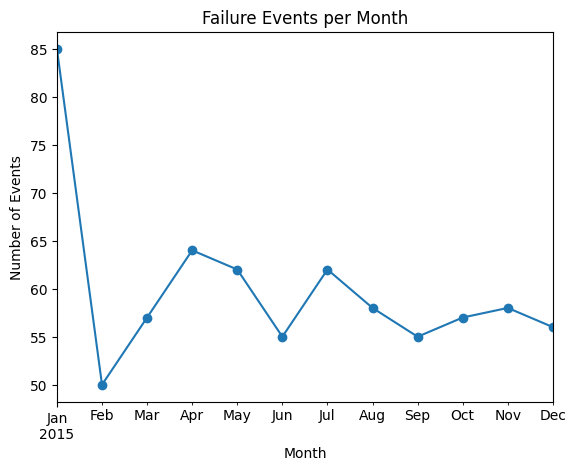

In [43]:
events_df.set_index('datetime').resample('M').size().plot(marker='o')
plt.title('Failure Events per Month')
plt.xlabel('Month')
plt.ylabel('Number of Events')
plt.show()

**Findings:**
- The data is clean with no missing values or duplicates
- There are failures across all 4 comps with Comp2 failing the most (259) and Comp3 failing the least (131)
- 761 failures, which become 719 events (42 events have 2 failures)
- Failure Events typically occur around 15-30 days for a given machine with a few events less than 15 days of the previous failure.
- Events have steady fluctuation throughout the year with a massive spike in January to start

# Telemetry EDA
<b>Dataset Description (from Kaggle):</b><br>
This is a telemetry time-series data. It consists of voltage, rotation, pressure, and vibration measurements collected from 100 machines in real time averaged over every hour collected during the year 2015.

**What to look for:**
1. What does the data look like?
2. What is the sampling  rate, and are there any gaps?
3. What do the sensor distributions look like?
4. Does sensors show any indication of downtime?
5. How long do extreme readings last?
6. Do sensor levels differ by machine or model?
7. How noisy is the data and would smoothing make the sensors easier to read?

In [44]:
general_analysis(telemetry_df)

Dataframe Shape:
 (876100, 6)

Column Types:
datetime     datetime64[ns]
machineID             int64
volt                float64
rotate              float64
pressure            float64
vibration           float64
dtype: object

Num of Missing Values Per Col:
datetime     0
machineID    0
volt         0
rotate       0
pressure     0
vibration    0
dtype: int64

Num of Duplicated Rows:
0

Date Range:
2015-01-01 06:00:00 - 2016-01-01 06:00:00


In [45]:
telemetry_df

,datetime,machineID,volt,rotate,pressure,vibration
0,2015-01-01 06:00:00,1,176.217853,418.504078,113.077935,45.087686
1,2015-01-01 07:00:00,1,162.879223,402.747490,95.460525,43.413973
2,2015-01-01 08:00:00,1,170.989902,527.349825,75.237905,34.178847
3,2015-01-01 09:00:00,1,162.462833,346.149335,109.248561,41.122144
4,2015-01-01 10:00:00,1,157.610021,435.376873,111.886648,25.990511
...,...,...,...,...,...,...
876095,2016-01-01 02:00:00,100,179.438162,395.222827,102.290715,50.771941
876096,2016-01-01 03:00:00,100,189.617555,446.207972,98.180607,35.123072
876097,2016-01-01 04:00:00,100,192.483414,447.816524,94.132837,48.314561
876098,2016-01-01 05:00:00,100,165.475310,413.771670,104.081073,44.835259


In [46]:
sensors = ['volt', 'rotate', 'pressure', 'vibration']

<b>calculate the gaps between sensor readings

In [47]:
telemetry_df = telemetry_df.sort_values(['machineID', 'datetime'])
gaps = telemetry_df.groupby('machineID')['datetime'].diff()
gaps.value_counts()

datetime
0 days 01:00:00    876000
Name: count, dtype: int64

In [48]:
telemetry_df[sensors].describe()

,volt,rotate,pressure,vibration
count,876100.000000,876100.000000,876100.000000,876100.000000
mean,170.777736,446.605119,100.858668,40.385007
std,15.509114,52.673886,11.048679,5.370361
min,97.333604,138.432075,51.237106,14.877054
25%,160.304927,412.305714,93.498181,36.777299
50%,170.607338,447.558150,100.425559,40.237247
75%,181.004493,482.176600,107.555231,43.784938
max,255.124717,695.020984,185.951998,76.791072


array([[<Axes: title={'center': 'volt'}>,
        <Axes: title={'center': 'rotate'}>],
       [<Axes: title={'center': 'pressure'}>,
        <Axes: title={'center': 'vibration'}>]], dtype=object)

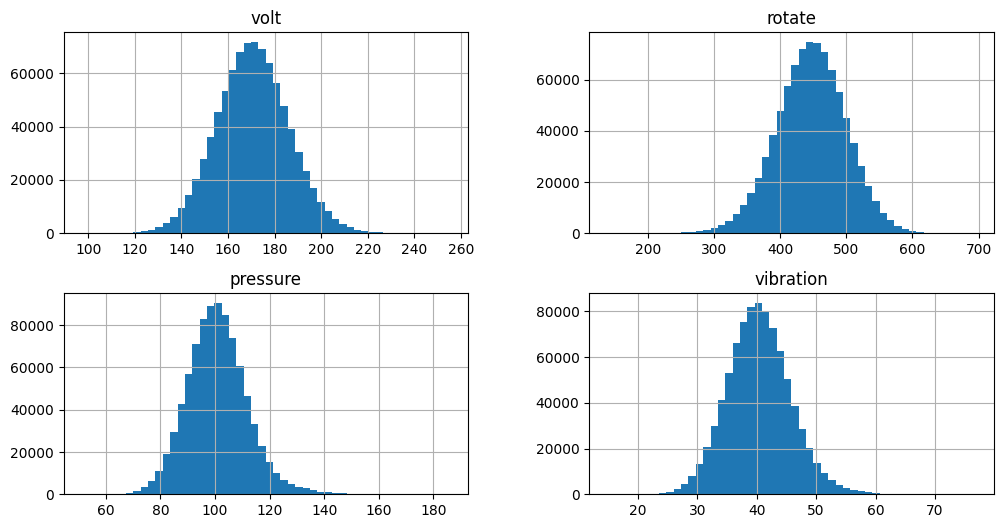

In [49]:
telemetry_df[['volt', 'rotate', 'pressure', 'vibration']].hist(bins=50, figsize=(12, 6))

<b> View raw telemetry data for machine 1 in 2015

array([<Axes: xlabel='datetime'>, <Axes: xlabel='datetime'>,
       <Axes: xlabel='datetime'>, <Axes: xlabel='datetime'>], dtype=object)

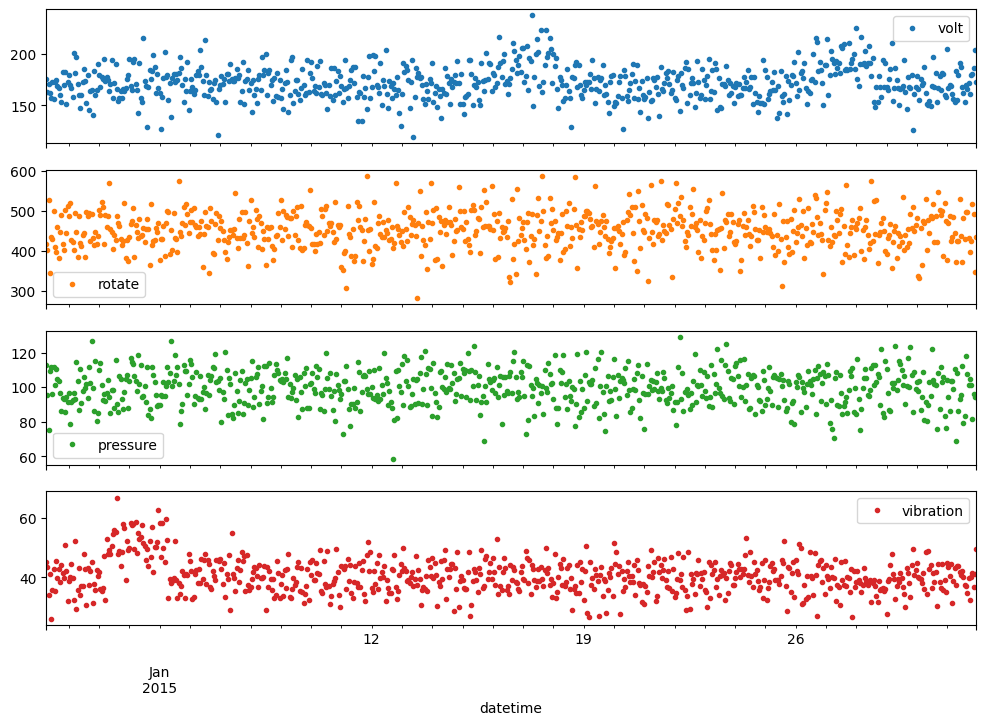

In [50]:
telemetry_m1_df = telemetry_df[telemetry_df["machineID"] == 1].set_index("datetime")
telemetry_m1_df.loc["2015-01", sensors].plot(subplots=True, figsize=(12, 8), style='.')

<b> Compare it to smoothed out data (rolling 24hrs mean)

array([<Axes: xlabel='datetime'>, <Axes: xlabel='datetime'>,
       <Axes: xlabel='datetime'>, <Axes: xlabel='datetime'>], dtype=object)

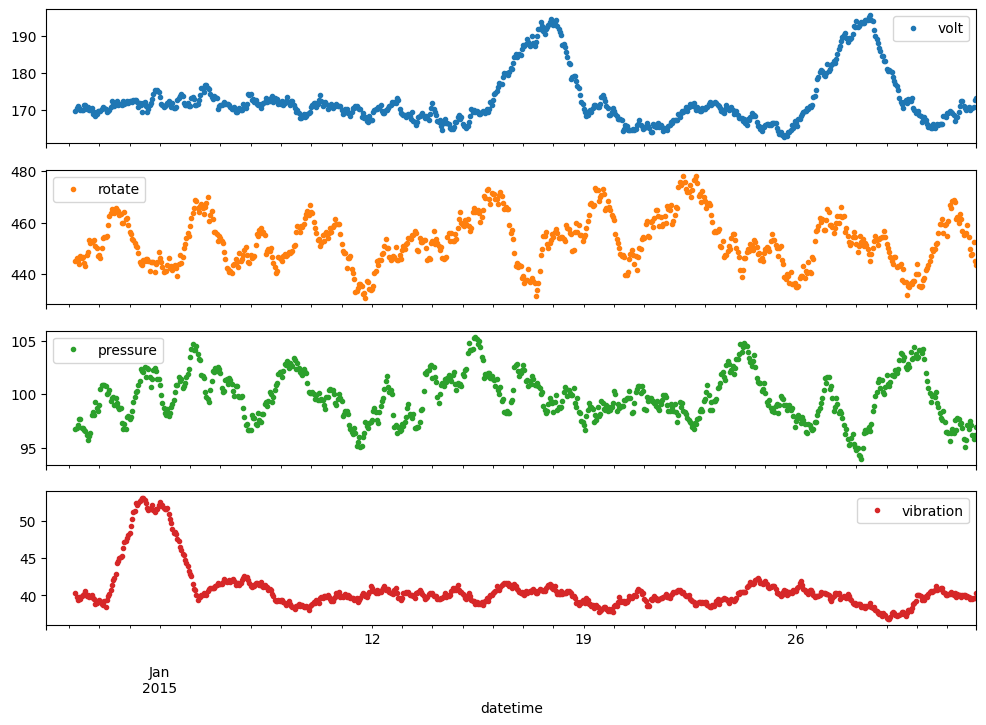

In [51]:
telemetry_m1_df.loc["2015-01", sensors].rolling(24).mean().plot(subplots=True, figsize=(12, 8), style='.')

<b> View a week of raw telemetry Data for Machine 1

array([<Axes: xlabel='datetime'>, <Axes: xlabel='datetime'>,
       <Axes: xlabel='datetime'>, <Axes: xlabel='datetime'>], dtype=object)

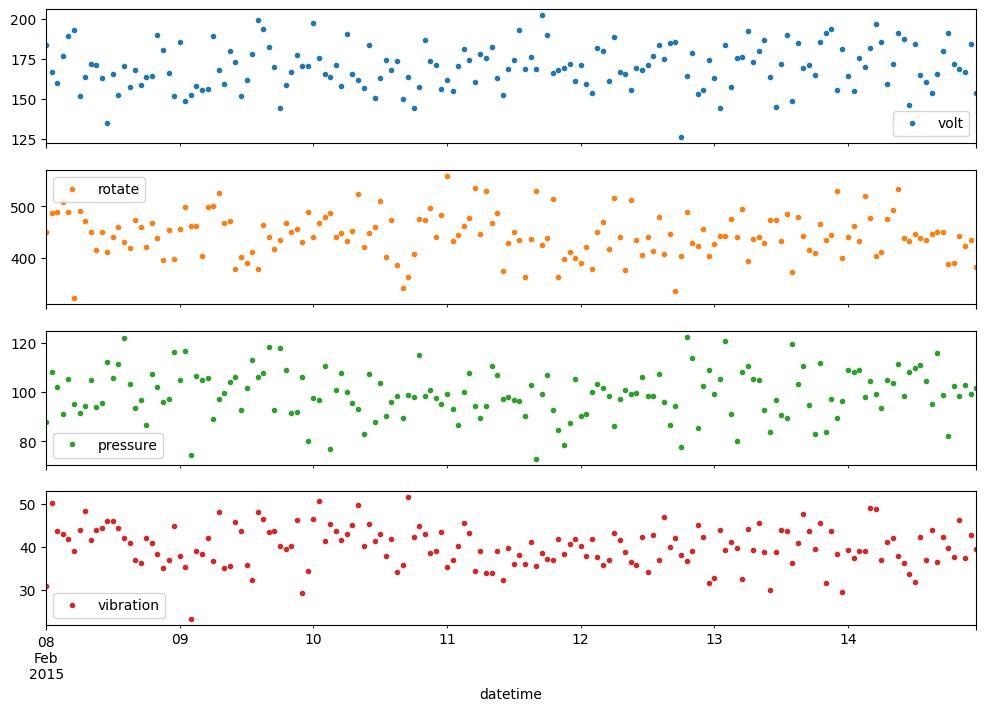

In [52]:
telemetry_m1_df.loc["2015-02-08":"2015-02-14", sensors].plot(subplots=True, figsize=(12, 8), style='.')

<b> Compare to Smoothout Data

array([<Axes: xlabel='datetime'>, <Axes: xlabel='datetime'>,
       <Axes: xlabel='datetime'>, <Axes: xlabel='datetime'>], dtype=object)

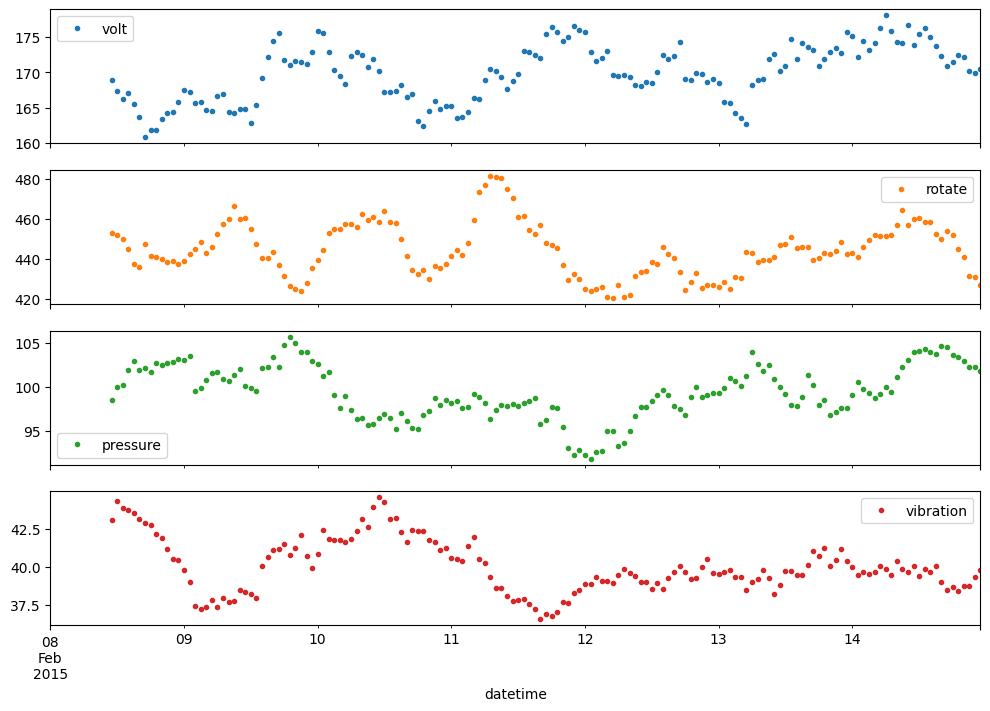

In [53]:
telemetry_m1_df.loc["2015-02-08":"2015-02-14", sensors].rolling(12).mean().plot(subplots=True, figsize=(12, 8), style='.')


<b> Average out each sensor value for each machine

In [54]:
telemetry_avg_per_machine_df = telemetry_df.groupby("machineID")[sensors].mean()

In [55]:
print(telemetry_avg_per_machine_df.describe())

             volt      rotate    pressure   vibration
count  100.000000  100.000000  100.000000  100.000000
mean   170.777736  446.605119  100.858668   40.385007
std      0.189982    0.814236    0.308647    0.124112
min    170.339950  444.766488  100.416061   40.142659
25%    170.653861  446.073076  100.631206   40.276075
50%    170.780240  446.582038  100.745276   40.358822
75%    170.902251  447.042344  101.085001   40.482825
max    171.267153  448.564574  101.705498   40.694790


<b> Average out each sensor value for each model type

In [56]:
telemetry_per_model_df = telemetry_df.merge(machines_df[["machineID", "model"]], on="machineID")

In [57]:
print(telemetry_per_model_df.groupby("model")[sensors].mean())

              volt      rotate    pressure  vibration
model                                                
model1  170.783416  446.373423  101.269060  40.437665
model2  170.723312  446.808776  101.216436  40.391633
model3  170.805606  446.512755  100.667661  40.395200
model4  170.773328  446.713797  100.672322  40.344008


<b> View outliers using Box Plots

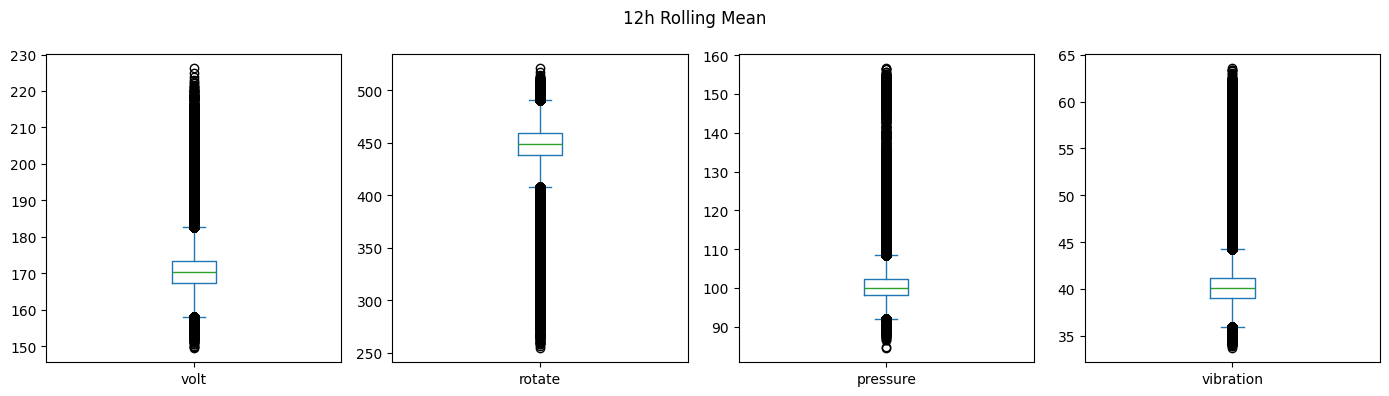

In [58]:
smoothed_telemetry_df = telemetry_df.groupby("machineID")[sensors].rolling(12).mean()
smoothed_telemetry_df.plot(kind="box", subplots=True, figsize=(14, 4), title="12h Rolling Mean")
plt.tight_layout()
plt.show()


**Findings:**
- The data is clean with no missing values or duplicates.
- Sampling rate is every hour for all 100 machines with no gaps.
- There are no signs of downtime as none of the sensors have a min of 0 (running all year round).
- Sensor Averages are nearly identical across machines and models.
- Hour readings are noisy. but a 12 hour rolling mean provides a lot more clarity to sensor behavior.
- All the sensors are live readings that bounce around a steady average, so nothing behaves like a counter. 
- Box plots show outliers with the smoothed out data providing a clearer indication of whether the outliers tend to be high or low values for the sensors.

# Analysis on Merged Dataframes

## Failures and Maintenance Merged

In [59]:
failures_maintenance_merged_df = failures_df.merge(
    maintenance_df,
    left_on=["machineID", "datetime", "failure"],
    right_on=["machineID", "datetime", "comp"],
    how="left",
)

In [60]:
len(failures_df)

761

In [61]:
len(maintenance_df)

3286

In [62]:
len(failures_maintenance_merged_df)

761

In [63]:
#failures_maintenance_merged_df.head(5)

<b>check cases where there was a failure but no repair

In [64]:
no_repair_df = failures_maintenance_merged_df[failures_maintenance_merged_df['comp'].isna()]

In [65]:
#no_repair_df

In [66]:
maintenance_failures_merged_df = maintenance_df.merge(
    failures_df,
    left_on=["machineID", "datetime", "comp"],
    right_on=["machineID", "datetime", "failure"],
    how="left",
).sort_values(["machineID", "comp", "datetime"]).reset_index(drop=True)

<b> Calculate the number of days since a a repair

In [67]:
maintenance_failures_merged_df["comp_age_days"] = (
    maintenance_failures_merged_df.groupby(["machineID", "comp"])["datetime"].diff().dt.days
)

In [68]:
maintenance_failures_merged_df = maintenance_failures_merged_df[
    maintenance_failures_merged_df["datetime"] >= "2015-01-01"
].reset_index(drop=True)

<b> Add label to the type of maintenance

In [69]:
maintenance_failures_merged_df["type"] = maintenance_failures_merged_df["failure"].notna().map(
    {True: "repair", False: "scheduled"}
)

In [70]:
maintenance_failures_merged_df.groupby(["comp", "type"])["comp_age_days"].describe()

count        mean        std   min   25%   50%     75%    max
comp  type                                                                    
comp1 repair     183.0   91.327869  56.254344  41.0  45.0  75.0  119.00  349.0
      scheduled  521.0   50.512476  57.148292  11.0  15.0  30.0   60.00  492.0
comp2 repair     256.0   76.671875  60.274159  26.0  30.0  60.0   90.00  323.0
      scheduled  507.0   47.429980  56.329288   5.0  15.0  15.0   47.50  349.0
comp3 repair     128.0   98.992188  61.207340  32.0  60.0  75.0  134.25  293.0
      scheduled  580.0   53.843103  56.402647  15.0  15.0  30.0   64.50  371.0
comp4 repair     176.0  102.204545  62.462452  45.0  60.0  75.0  135.00  395.0
      scheduled  535.0   48.293458  53.662647  15.0  15.0  30.0   60.00  335.0

In [71]:
len(maintenance_failures_merged_df[maintenance_failures_merged_df['type'] == 'repair'])/len(maintenance_failures_merged_df)

0.25744975744975745

In [72]:
len(maintenance_failures_merged_df[maintenance_failures_merged_df['type'] == 'scheduled'])/len(maintenance_failures_merged_df)

0.7425502425502426

### Findings:

- 743 of 761 failures have a matching repair in the maintenance log.
- The other 18 all occur at `2015-01-02 03:00`, only 21h after telemetry starts. They are excluded since there's no data before them (719 to 702 events).
- 2014 is excluded since we dont have any failure data until 2015
- ~26% of maintenance are repairs and ~74% are scheduled.
- Failed components are typically ~2x older than scheduled replacements.
- Failures almost never happen in a component's first ~30 days.
- Idea to test later: component age as a filter, e.g. only alert if the part is >30 days old


## Failures and Errors Merged

In [73]:
failures_errors_merged_df = failures_df.merge(
    errors_df, on="machineID", suffixes=("_failure", "_error")
)

In [74]:
len(failures_df[failures_df['machineID'] == 1])

7

In [75]:
len(errors_df[errors_df['machineID'] == 1])

35

In [76]:
failures_errors_merged_df[failures_errors_merged_df['machineID'] == 1]

,datetime_failure,machineID,failure,datetime_error,errorID
0,2015-01-05 06:00:00,1,comp4,2015-01-03 07:00:00,error1
1,2015-01-05 06:00:00,1,comp4,2015-01-03 20:00:00,error3
2,2015-01-05 06:00:00,1,comp4,2015-01-04 06:00:00,error5
3,2015-01-05 06:00:00,1,comp4,2015-01-10 15:00:00,error4
4,2015-01-05 06:00:00,1,comp4,2015-01-22 10:00:00,error4
...,...,...,...,...,...
240,2015-12-16 06:00:00,1,comp4,2015-10-16 03:00:00,error3
241,2015-12-16 06:00:00,1,comp4,2015-10-16 06:00:00,error2
242,2015-12-16 06:00:00,1,comp4,2015-10-16 06:00:00,error3
243,2015-12-16 06:00:00,1,comp4,2015-11-10 04:00:00,error3


<b> How many hours before the failure each error happened

In [77]:
failures_errors_merged_df["hours_before"] = (
    failures_errors_merged_df["datetime_failure"] - failures_errors_merged_df["datetime_error"]
).dt.total_seconds() / 3600

In [78]:
#failure_errors_merged_df

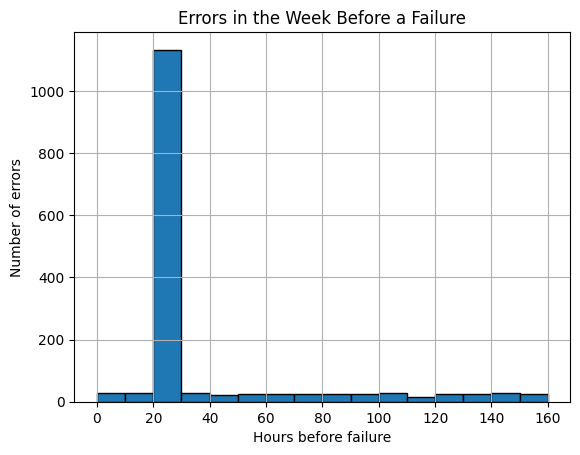

In [79]:
mask = (
    (failures_errors_merged_df["hours_before"] > 0) &
    (failures_errors_merged_df["hours_before"] <= 168)
)


failures_errors_merged_df[mask]["hours_before"].hist(bins=range(0, 170, 10), edgecolor="black")
plt.title("Errors in the Week Before a Failure")
plt.xlabel("Hours before failure")
plt.ylabel("Number of errors")
plt.show()


<b> Keep only errors in the 35 hours before the failure (based on distribution)


In [80]:
failures_errors_merged_df = failures_errors_merged_df[
    (failures_errors_merged_df["hours_before"] > 0) &
    (failures_errors_merged_df["hours_before"] <= 35)
].reset_index(drop=True)

In [81]:
#failures_errors_merged_df

<b> Keep only 1 instance of unique each error-failure for each failure

In [82]:
failures_errors_unique_df = failures_errors_merged_df.drop_duplicates(
    ["machineID", "datetime_failure", "failure", "errorID"]
)
failures_errors_unique_df

,datetime_failure,machineID,failure,datetime_error,errorID,hours_before
0,2015-01-05 06:00:00,1,comp4,2015-01-03 20:00:00,error3,34.0
1,2015-01-05 06:00:00,1,comp4,2015-01-04 06:00:00,error5,24.0
2,2015-03-06 06:00:00,1,comp1,2015-03-05 06:00:00,error1,24.0
3,2015-04-20 06:00:00,1,comp2,2015-04-19 06:00:00,error2,24.0
4,2015-04-20 06:00:00,1,comp2,2015-04-19 06:00:00,error3,24.0
...,...,...,...,...,...,...
1204,2015-12-14 06:00:00,99,comp4,2015-12-13 06:00:00,error5,24.0
1205,2015-02-12 06:00:00,100,comp1,2015-02-11 06:00:00,error1,24.0
1206,2015-09-10 06:00:00,100,comp1,2015-09-09 06:00:00,error1,24.0
1207,2015-12-09 06:00:00,100,comp2,2015-12-08 06:00:00,error2,24.0


In [83]:
failures_with_error_count_df = pd.crosstab(failures_errors_unique_df ["failure"], failures_errors_unique_df ["errorID"])
failures_with_error_count_df

errorID,error1,error2,error3,error4,error5
failure,,,,,
comp1,184,11,14,9,6
comp2,13,256,256,17,14
comp3,5,11,11,128,6
comp4,13,21,24,9,176


In [84]:
failures_with_error_pct_df = failures_with_error_count_df.div(failures_df["failure"].value_counts(), axis=0).mul(100).round(1)
failures_with_error_pct_df

errorID,error1,error2,error3,error4,error5
failure,,,,,
comp1,95.8,5.7,7.3,4.7,3.1
comp2,5.0,98.8,98.8,6.6,5.4
comp3,3.8,8.4,8.4,97.7,4.6
comp4,7.3,11.7,13.4,5.0,98.3


<b> Plot the distribution of error appearance before its respective failure

In [85]:
#failures_errors_merged_df

<b> Calculate the percentage of each error type that is followed by a failure within 35 hours


In [86]:
errors_followed_by_failure_df = failures_errors_merged_df.drop_duplicates(["machineID", "datetime_error", "errorID"])

pct_errors_followed_by_failure = (
    errors_followed_by_failure_df["errorID"].value_counts() / errors_df["errorID"].value_counts()
)
pct_errors_followed_by_failure


errorID
error1    0.200990
error2    0.280364
error3    0.340095
error4    0.207703
error5    0.505618
Name: count, dtype: float64

### Findings:
- Most Errors resulting in a Failure occur around 24 hours before it. 
- Each Component appears to have its own matching error type: 
    - comp1 → error1
    - comp2 → error2 and error3
    - comp3 → error4
    - comp4 → error5
- However, there is a low percentage of errors that are actually followed by a failure (false positives)

## Machine and Failures Merged

In [87]:
events_per_machine = events_df.groupby("machineID").size().rename("n_events")

machines_events_merged_df = machines_df.merge(
    events_per_machine, on="machineID", how="left"
).fillna({"n_events": 0})

machines_events_merged_df

,machineID,model,age,n_events
0,1,model3,18,7.0
1,2,model4,7,3.0
2,3,model3,8,5.0
3,4,model3,7,6.0
4,5,model3,2,7.0
...,...,...,...,...
95,96,model2,10,5.0
96,97,model2,14,7.0
97,98,model2,20,14.0
98,99,model1,14,19.0


In [88]:
machines_events_merged_df.groupby("model")["n_events"].agg(["mean", "count"])

,mean,count
model,,
model1,10.937500,16
model2,9.411765,17
model3,6.057143,35
model4,5.375000,32


In [89]:
failures_with_model = failures_df.merge(machines_df, on="machineID")
pd.crosstab(failures_with_model["model"], failures_with_model["failure"])

failure,comp1,comp2,comp3,comp4
model,,,,
model1,33,46,68,42
model2,30,41,63,34
model3,68,89,0,64
model4,61,83,0,39


In [90]:
machines_events_merged_df[["age", "n_events"]].corr()

,age,n_events
age,1.000000,0.457349
n_events,0.457349,1.000000


In [91]:
print(machines_events_merged_df.groupby("model")["age"].mean())

model
model1    12.250000
model2    12.764706
model3    12.028571
model4     9.343750
Name: age, dtype: float64


**Findings:**
- Per machine, comp1 and comp2 fail at about the same rate on every model. Models 1 and 2 only have more failures overall because they are the only ones with comp3 failures.
- Models 3 and 4 have no component 3 failures at all.
- Older machines tend to have more failure events (correlation of 0.46 between age and number of events).


## Maintenance, Failures and Telemetry Merged

In [92]:
sensors

['volt', 'rotate', 'pressure', 'vibration']

<b> Take a look at the Telemetry data for a specific failure for each Failure Comp

In [93]:
def plot_telemetry_data_around_failure(comp, index=0, days=5):
    failure = failures_df[failures_df["failure"] == comp].iloc[index]

    start = failure["datetime"] - pd.Timedelta(days=days)
    end = failure["datetime"] + pd.Timedelta(days=days)

    around_failure_df = telemetry_df[
        (telemetry_df["machineID"] == failure["machineID"]) &
        (telemetry_df["datetime"] >= start) &
        (telemetry_df["datetime"] <= end)
    ]

    smoothed_df = around_failure_df.set_index("datetime")[sensors].rolling(12).mean()
    axes = smoothed_df.plot(subplots=True, figsize=(12, 8), title=f"Telemetry Data around {comp} Failure")
    for ax in axes:
        ax.axvline(failure["datetime"], color="black", linestyle="--")
    plt.show()


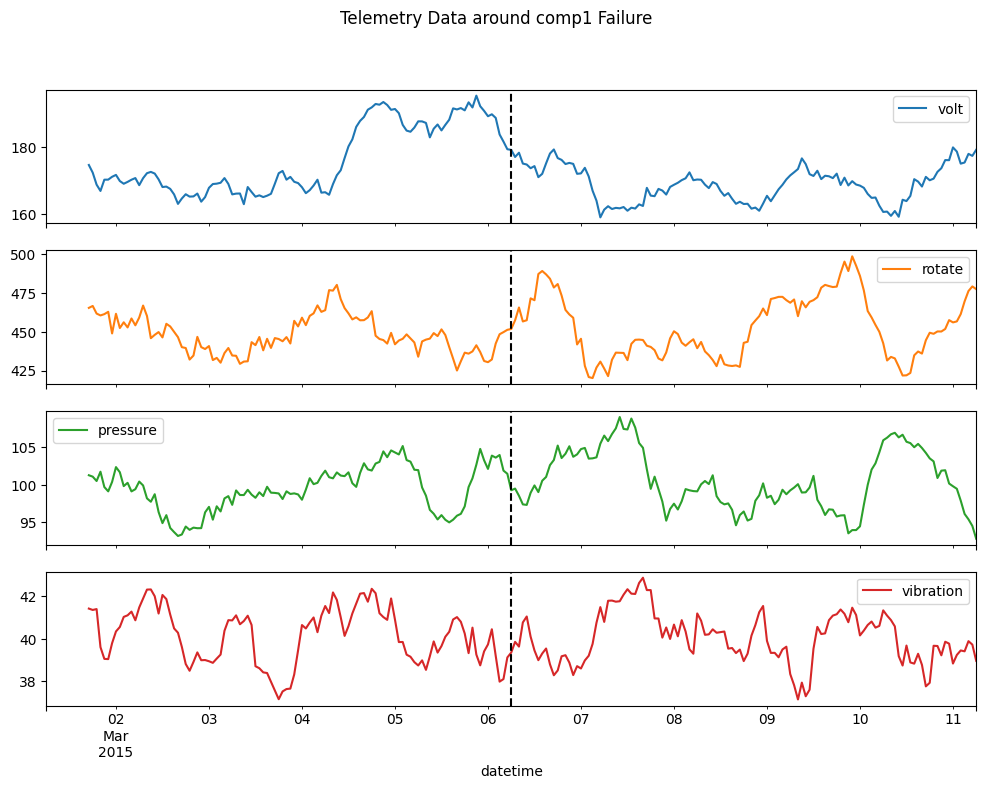

In [94]:
plot_telemetry_data_around_failure('comp1')
#plot_telemetry_data_around_failure('comp2')
#plot_telemetry_data_around_failure('comp3')
#plot_telemetry_data_around_failure('comp4')

<b> Averaged across all failures for each component

In [95]:
def plot_average_around_failure(comp, days=5):
    comp_failures_df = failures_df[failures_df["failure"] == comp]

    windows = []
    for _, failure in comp_failures_df.iterrows():
        start = failure["datetime"] - pd.Timedelta(days=days)
        end = failure["datetime"] + pd.Timedelta(days=days)

        window_df = telemetry_df[
            (telemetry_df["machineID"] == failure["machineID"]) &
            (telemetry_df["datetime"] >= start) &
            (telemetry_df["datetime"] <= end)
        ].copy()

        window_df["hours_from_failure"] = (window_df["datetime"] - failure["datetime"]).dt.total_seconds() / 3600
        windows.append(window_df)

    all_windows_df = pd.concat(windows)
    average_df = all_windows_df.groupby("hours_from_failure")[sensors].mean()

    axes = average_df.plot(subplots=True, figsize=(12, 8), title=f"Average telemetry around {comp} failures")
    for ax in axes:
        ax.axvline(0, color="black", linestyle="--")
    plt.show()


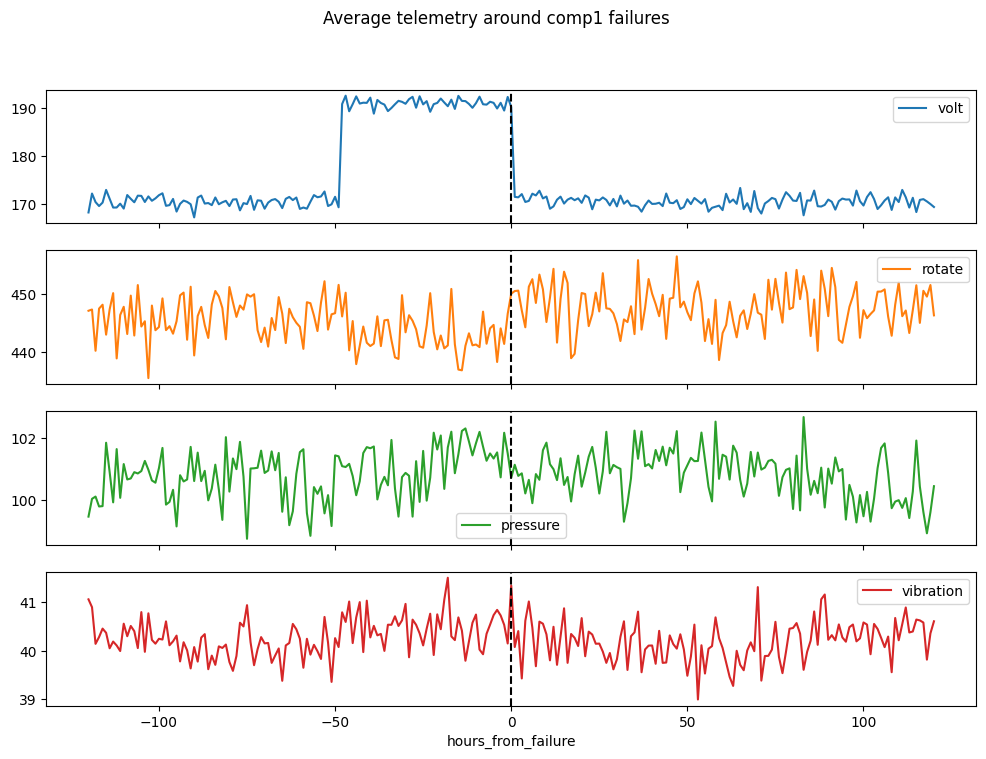

In [96]:
plot_average_around_failure("comp1")

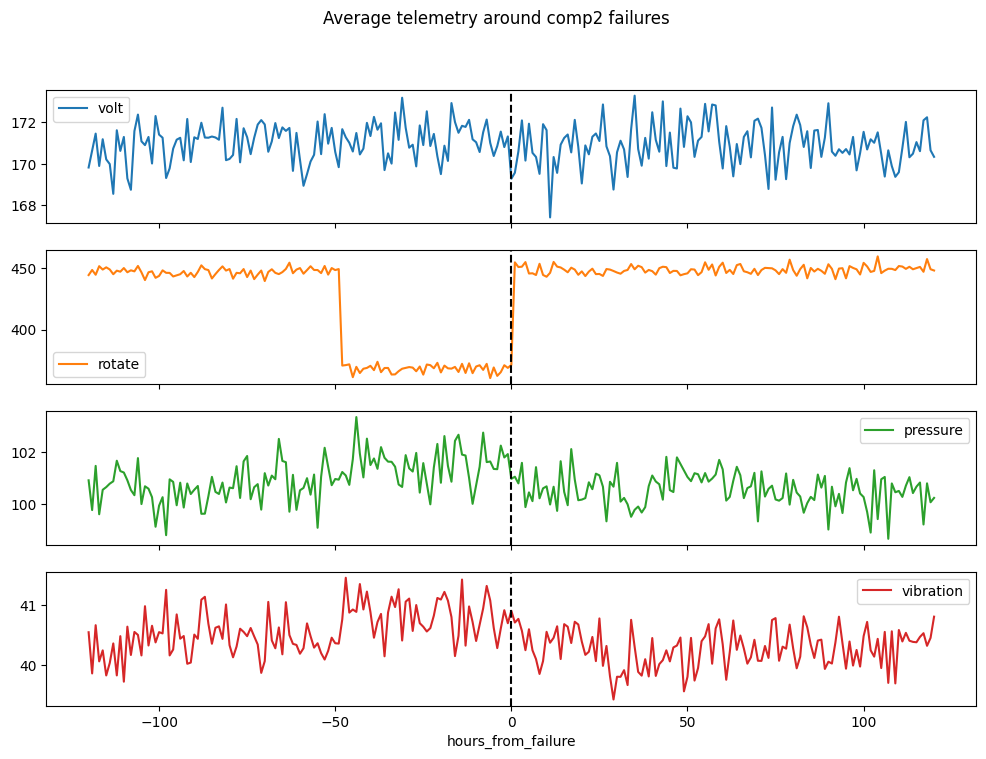

In [97]:
plot_average_around_failure("comp2")

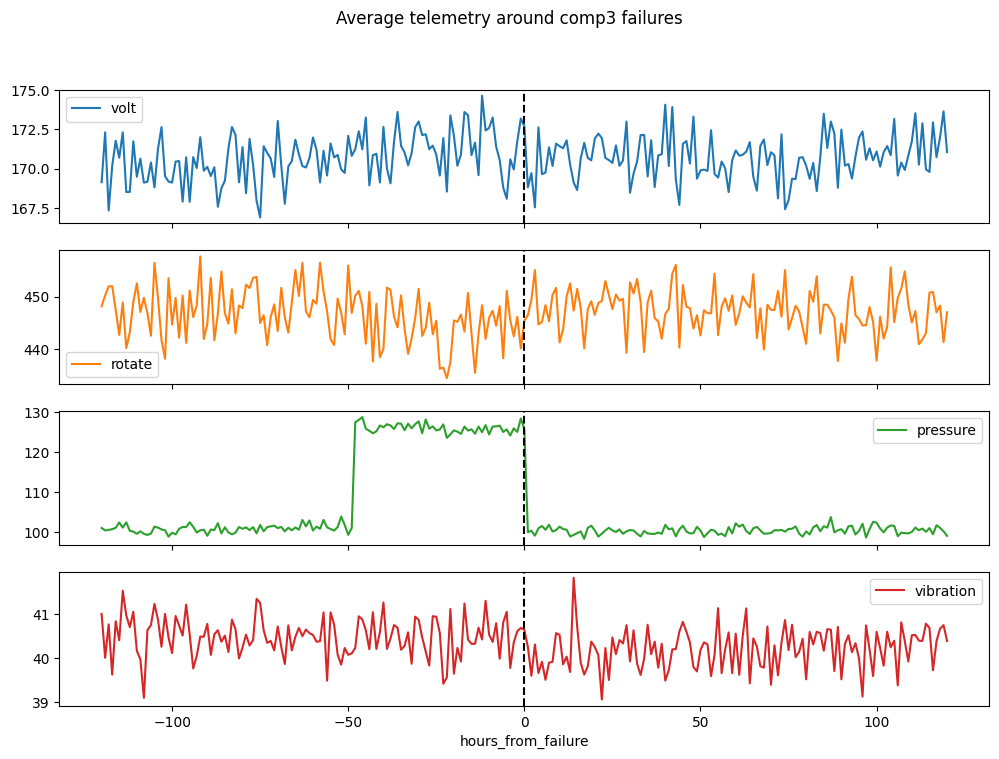

In [98]:
plot_average_around_failure("comp3")

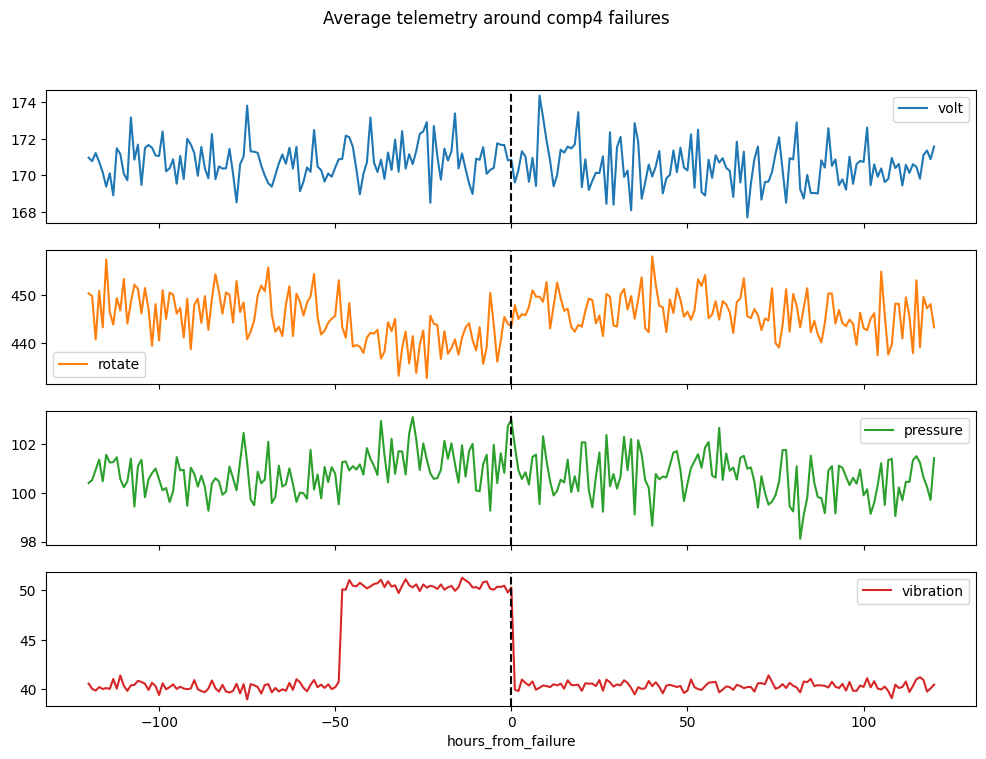

In [99]:
plot_average_around_failure("comp4")

**Findings:**
- Each component failure has its own matching sensor that shifts before it:
    - comp1 → volt (goes up)
    - comp2 → rotate (goes down)
    - comp3 → pressure (goes up)
    - comp4 → vibration (goes up)
- The shift happens suddenly around 48 hours before the failure and stays there until the failure.
- The other sensors don't change and just show normal noise.
- Right after the failure the sensor goes straight back to normal since the component gets replaced.
- Since maintenance is also a component replacement, there is no recovery period to worry about after repairs or scheduled maintenance.
- Telemetry data essentially gives a warning 48hrs before.
